In [1]:
import torch  
import torch.nn as nn  
import torch.optim as optim
import torch.nn.functional as F 
from data_setup import RotatedMNIST, create_dataloaders
from vae_setup import VAE
from model import MultiTaskDNN
from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

In [2]:
# Training configs
training_data_cfg = {
    'dataset_path': './DNN_Data',
    'batch_size': 32,
    'num_workers': 0,  # Set to 0 to avoid multiprocessing issues during plotting
    'max_digit': 9,
    'max_rotation_degrees': 360
}

training_model_cfg = {
    'input_shape': 784,
    'shared_layers': 3,
    'task_layers': 3,
    'shared_nodes': 64,
    'task_nodes': 32,
    'digit_out': 10,
    'parity_out': 2,
    'rotation_out': 1
}

train_cfg = {
    'activation': 'relu'
}

# Trainig/test loaders
train_loader, test_loader = create_dataloaders(training_data_cfg)

# Load model from filepath
def load_DNN_model(filename):
    new_model = MultiTaskDNN(training_model_cfg, train_cfg)
    state_dict = torch.load(filename, map_location="cpu", weights_only=True)
    new_model.load_state_dict(state_dict, strict=True)
    return new_model

BASE_MODEL_FILEPATH = "wide-models/wide-1000-epoch-model.pkl"
base_model = load_DNN_model(BASE_MODEL_FILEPATH)

In [3]:
# VAE loss function, where total loss = reconstruction loss + KL divergence
def vae_loss(recon, X, mu, logvar, likelihood):
    # Reconstruction: negative log-likelihood, averaged over batch
    if likelihood == "gaussian":
        # Gaussian NLL ∝ MSE
        recon_loss = F.mse_loss(recon, X, reduction="mean")
    elif likelihood == "poisson":
        # Poisson NLL = mean over batch of sum over units (λ - k·log λ)
        log_factorial = torch.lgamma(X + 1)
        recon_loss = (recon - X * torch.log(recon + 1e-8) + log_factorial).sum(dim=1).mean()
        recon_loss = recon_loss / (X.mean() + 1e-8)
    # KL averaged over batch
    kl_loss = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1).mean()
    return recon_loss + kl_loss, recon_loss, kl_loss

# Use GPU if available  
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# VAE training function
def train_VAE(X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2):
    assert likelihood in ("gaussian", "poisson")
	
    # Initialize batches and model
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True)
    
    input_dim = X.shape[1]
    vae_model = VAE(input_dim=input_dim, latent_dim=latent_dim, likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=1e-3)
    
    # Track losses 
    train_losses = []
    recon_losses = []
    kl_losses = []
    
    # Training loop
    vae_model.train()
    for epoch in range(n_epochs+1):
        total_train_loss = 0
        total_recon_loss = 0
        total_kl_loss = 0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, mu, logvar = vae_model(xb)
            
            train_loss, recon_loss, kl_loss = vae_loss(recon, xb, mu, logvar, likelihood)
            total_train_loss += train_loss.item()
            total_recon_loss += recon_loss.item()
            total_kl_loss += kl_loss.item()
            
            train_loss.backward()
            optimizer.step()

        train_losses.append(total_train_loss)
        recon_losses.append(total_recon_loss)
        kl_losses.append(total_kl_loss)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: loss={total_train_loss:.3f} recon={total_recon_loss:.3f} kl={total_kl_loss:.3f}")

	# Return model and training logs
    logs = {"training_losses": train_losses, "recon_losses": recon_losses, "kl_losses": kl_losses}
    return vae_model, logs

In [4]:
# Collect labels/activations
digit_labels = []
rot_labels = []
first_digit_layer_X = []
last_digit_layer_X = []

base_model.eval()
with torch.no_grad():
    for images, digits, angle_rad, angle_deg in test_loader:
        # Make predictions
        digit_logits, parity_logits, rot_preds, acts = base_model(images)

        # Record digit and rotation labels
        digit_labels.extend(list(digits))
        rot_labels.extend(list(angle_rad))

        # Record first and last digit layer activations
        first_digit_layer_X.append(acts["Digit_Layer_0"].detach().cpu())
        last_digit_layer_X.append(acts["Digit_Layer_2"].detach().cpu())

# Stack into single tensors: [N, 32]
first_digit_layer_X = torch.cat(first_digit_layer_X, dim=0)
last_digit_layer_X  = torch.cat(last_digit_layer_X,  dim=0)

In [5]:
# Set training parameters 
n_epochs = 100
batch_size = 64
learning_rate = 1e-3
likelihood = "gaussian"

# Train VAE model
first_layer_vae_model, logs = train_VAE(first_digit_layer_X, likelihood, batch_size, n_epochs, learning_rate, latent_dim=2)

epoch 0: loss=66.280 recon=65.589 kl=0.691


epoch 10: loss=63.678 recon=63.617 kl=0.061


epoch 20: loss=63.446 recon=63.421 kl=0.025


epoch 30: loss=63.299 recon=63.290 kl=0.009


epoch 40: loss=63.195 recon=63.191 kl=0.004


epoch 50: loss=63.109 recon=63.108 kl=0.001


epoch 60: loss=63.074 recon=63.073 kl=0.001


epoch 70: loss=63.038 recon=63.038 kl=0.000


epoch 80: loss=63.083 recon=63.083 kl=0.000


epoch 90: loss=62.953 recon=62.953 kl=0.000


epoch 100: loss=63.029 recon=63.028 kl=0.001


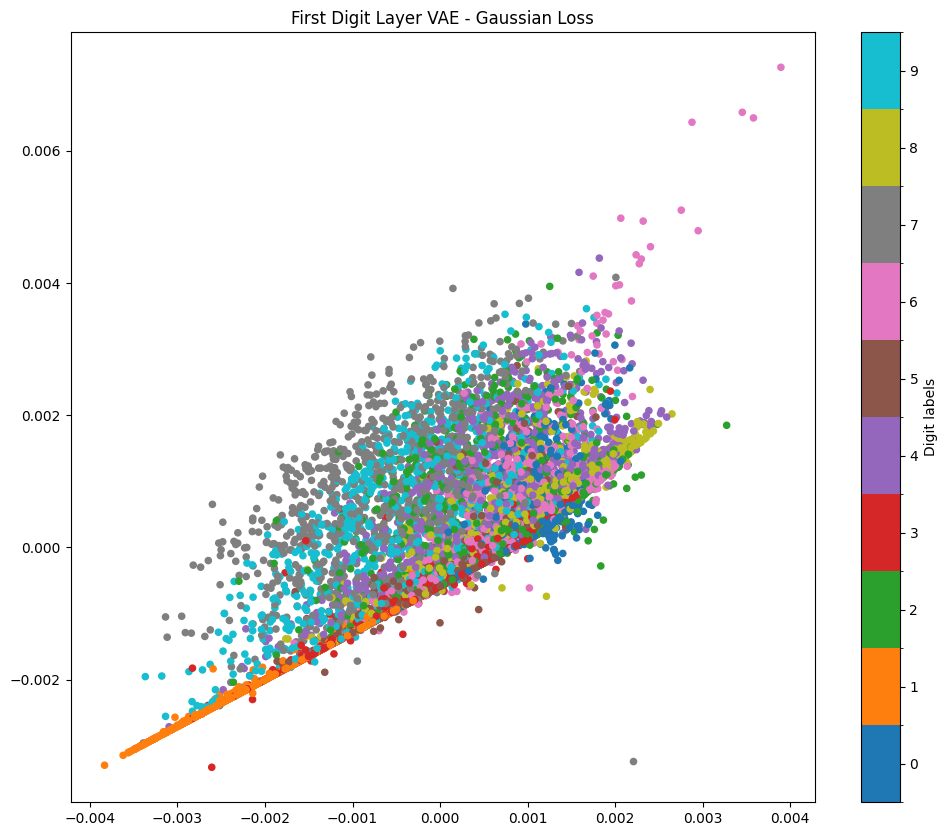

In [6]:
first_layer_vae_model.eval()
with torch.no_grad():
    mu_all, _ = first_layer_vae_model.encoder(first_digit_layer_X) # encode all available data
    Z = mu_all.cpu().numpy()
    
cmap = plt.get_cmap("tab10")   # 10 distinct colors
norm = mcolors.BoundaryNorm(boundaries=np.arange(-1/2, 10), ncolors=10)

sc = plt.scatter(Z[:, 0], Z[:, 1], c=digit_labels, cmap=cmap, norm=norm, s=20)
cbar = plt.colorbar(sc, ticks=range(10))
cbar.set_label("Digit labels")
plt.title("First Digit Layer VAE - Gaussian Loss")

fig = plt.gcf()
fig.set_size_inches(12, 10)

plt.show()

In [7]:
def graph_VAE_latent_space(vae_model, X, label, transform=None):
# Do forward pass on VAE encoding of the digit-layer activations
    vae_model.eval()
    with torch.no_grad():
        mu_all, sd_all = vae_model.encoder(X)  # [N, 2], [N, 2]
        Z = mu_all.cpu().numpy()

     # Apply fitted Procrustes transform (if any) before plotting
    if transform is not None:
        Z = apply_procrustes_similarity(Z, transform)

    # Calculate per-digit latent variance for both dimensions 
    var_np = sd_all ** 2 
    digits_np = np.asarray([int(d) for d in digit_labels])
    
    unique_digits = range(10)
    # Find avg variance per digit / latent dimension
    avg_var_per_digit = np.stack([var_np[digits_np == d].mean(axis=0) for d in unique_digits], axis=0)
    
    # Make figure: VAE scatter (left), per-digit latent variance (right)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Left: VAE latent space scatter plot
    cmap = plt.get_cmap("tab10")
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-1/2, 10), ncolors=10)
    sc = ax1.scatter(Z[:, 0], Z[:, 1], c=digit_labels, cmap=cmap, norm=norm, s=20)

    # Color in digits 
    cbar = fig.colorbar(sc, ax=ax1, ticks=unique_digits)
    cbar.set_label("Digit labels")
    ax1.set_title(f"{label} VAE Latent Space")
    ax1.set_xlabel("z[0]")
    ax1.set_ylabel("z[1]")
    
    # Right: grouped bars, one group per digit, one bar per latent dim
    x = np.arange(len(unique_digits))
    width = 0.4
    ax2.bar(x - width/2, avg_var_per_digit[:, 0], width, label="z[0] Var", color="steelblue")
    ax2.bar(x + width/2, avg_var_per_digit[:, 1], width, label="z[1] Var", color="darkorange")
    ax2.set_xticks(x)
    ax2.set_xticklabels(unique_digits)
    ax2.set_xlabel("digit")
    ax2.set_ylabel("mean latent variance")
    ax2.set_title(f"{label} Avg. Latent Variance per Digit")
    ax2.legend()
    ax2.grid(axis="y", alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [8]:
def procrustes_latent_penalty(mu_student, mu_teacher, center=True, scale=True):
    """
    Procrustes distance between two sets of 2D latent codes.

    Takes in both mu predictions from student and teacher as input.
    Returns Procrustes distance, i.e. squared residual norm.
    """
    # Center
    if center:
        s = mu_student - mu_student.mean(dim=0, keepdim=True)
        t = mu_teacher - mu_teacher.mean(dim=0, keepdim=True)
    else:
        s, t = mu_student, mu_teacher

    # Normalize scale between both 
    if scale:
        s = s / (s.norm() + 1e-8)
        t = t / (t.norm() + 1e-8)

    # Optimal orthogonal transform Q minimizing ||s Q - t||_F  (solve on teacher side)
    # M = s^T t ; SVD M = U S V^T ; Q = U V^T
    M = s.t() @ t
    U, _, Vt = torch.linalg.svd(M)
    Q = U @ Vt

    # Residual after alignment
    residual = s @ Q - t
    # Normalize so the penalty is scale-free and comparable across batches
    denom = t.norm() + 1e-8
    return (residual.norm() / denom) ** 2   # squared relative Procrustes distance

def train_VAE_with_procrustes(X, likelihood, batch_size, n_epochs, learning_rate,
                              teacher_model, proc_lambda=0.1,
                              latent_dim=2, procrustes_scale=True):
    assert likelihood in ("gaussian", "poisson")
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True)

    input_dim = X.shape[1]
    vae_model = VAE(input_dim=input_dim, latent_dim=latent_dim,
                    likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=learning_rate)

    teacher_model.eval()
    for p in teacher_model.parameters():
        p.requires_grad_(False)          # freeze teacher

    train_losses, recon_losses, kl_losses, proc_losses = [], [], [], []

    vae_model.train()
    for epoch in range(n_epochs + 1):
        tot = rec = kl = proc = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, mu, logvar = vae_model(xb)

            # Calculate base VAE loss
            base_loss, recon_loss, kl_loss = vae_loss(recon, xb, mu, logvar, likelihood)

            # Find teacher latents for the same batch
            with torch.no_grad():
                mu_teacher, _ = teacher_model.encoder(xb)

            # Calculate Procrustes penalty
            proc_loss = procrustes_latent_penalty(mu, mu_teacher, scale=procrustes_scale)
            
            # Combine together for total loss, scaling proc_loss by proc_lambda
            proc_loss *= proc_lambda
            total = base_loss + proc_loss
            total.backward()
            optimizer.step()

            tot  += total.item()
            rec  += recon_loss.item()
            kl   += kl_loss.item()
            proc += proc_loss.item()

        train_losses.append(tot); recon_losses.append(rec)
        kl_losses.append(kl);     proc_losses.append(proc)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: total={tot:.3f} recon={rec:.3f} "
                  f"kl={kl:.3f} proc={proc:.3f}")

    logs = {"training_losses": train_losses, "recon_losses": recon_losses,
            "kl_losses": kl_losses, "procrustes_losses": proc_losses}
    return vae_model, logs

In [9]:
# Set training parameters 
n_epochs = 100
batch_size = 64
learning_rate = 1e-3 
likelihood = "gaussian"
teacher_model = first_layer_vae_model
proc_lambda = 10000

# Train VAE model
last_layer_vae_model, logs = train_VAE_with_procrustes(last_digit_layer_X, likelihood, batch_size, n_epochs, learning_rate,
                                       teacher_model, proc_lambda=proc_lambda, latent_dim=2)

epoch 0: total=652542.422 recon=169.967 kl=41.611 proc=652330.844


epoch 10: total=144577.822 recon=170.074 kl=13.079 proc=144394.668


epoch 20: total=100791.762 recon=169.198 kl=15.120 proc=100607.444


epoch 30: total=82727.257 recon=168.488 kl=17.831 proc=82540.939


epoch 40: total=68644.695 recon=168.033 kl=20.471 proc=68456.192


epoch 50: total=61535.262 recon=167.554 kl=23.469 proc=61344.239


epoch 60: total=55142.224 recon=166.749 kl=27.394 proc=54948.081


epoch 70: total=50434.309 recon=166.455 kl=30.516 proc=50237.338


epoch 80: total=47255.126 recon=166.085 kl=33.962 proc=47055.079


epoch 90: total=39138.203 recon=165.772 kl=36.932 proc=38935.499


epoch 100: total=36911.193 recon=165.321 kl=40.730 proc=36705.141


In [10]:
def fit_procrustes_similarity(Z_src, Z_ref, center=True, scale=True):
    """
    Fit transform (s, R, t) mapping Z_src -> Z_ref in the least-squares sense:
        Z_ref ≈ s * (Z_src - mu_src) @ R + mu_ref
    Z_*: [N, D] numpy arrays, SAME row correspondence.
    Returns dict with 'mu_src', 'mu_ref', 'R', 's'.
    """
    Z_src = np.asarray(Z_src, dtype=np.float64)
    Z_ref = np.asarray(Z_ref, dtype=np.float64)
    assert Z_src.shape == Z_ref.shape

    mu_src = Z_src.mean(axis=0) if center else np.zeros(Z_src.shape[1])
    mu_ref = Z_ref.mean(axis=0) if center else np.zeros(Z_ref.shape[1])
    S = Z_src - mu_src
    T = Z_ref - mu_ref

    # Orthogonal Procrustes: minimize ||S R - T||_F  s.t. R^T R = I
    M = S.T @ T
    U, _, Vt = np.linalg.svd(M)
    R = U @ Vt                       # [D, D], orthogonal (may be a reflection)

    # Optional isotropic scale (similarity Procrustes)
    if scale:
        # optimal scalar s = trace(S^T T R^T ... ) / ||S||_F^2
        denom = np.sum(S * S)
        num = np.sum((S @ R) * T)
        s = (num / denom) if denom > 0 else 1.0
    else:
        s = 1.0

    return {"mu_src": mu_src, "mu_ref": mu_ref, "R": R, "s": s}


def apply_procrustes_similarity(Z, transform):
    return transform["s"] * (Z - transform["mu_src"]) @ transform["R"] + transform["mu_ref"]

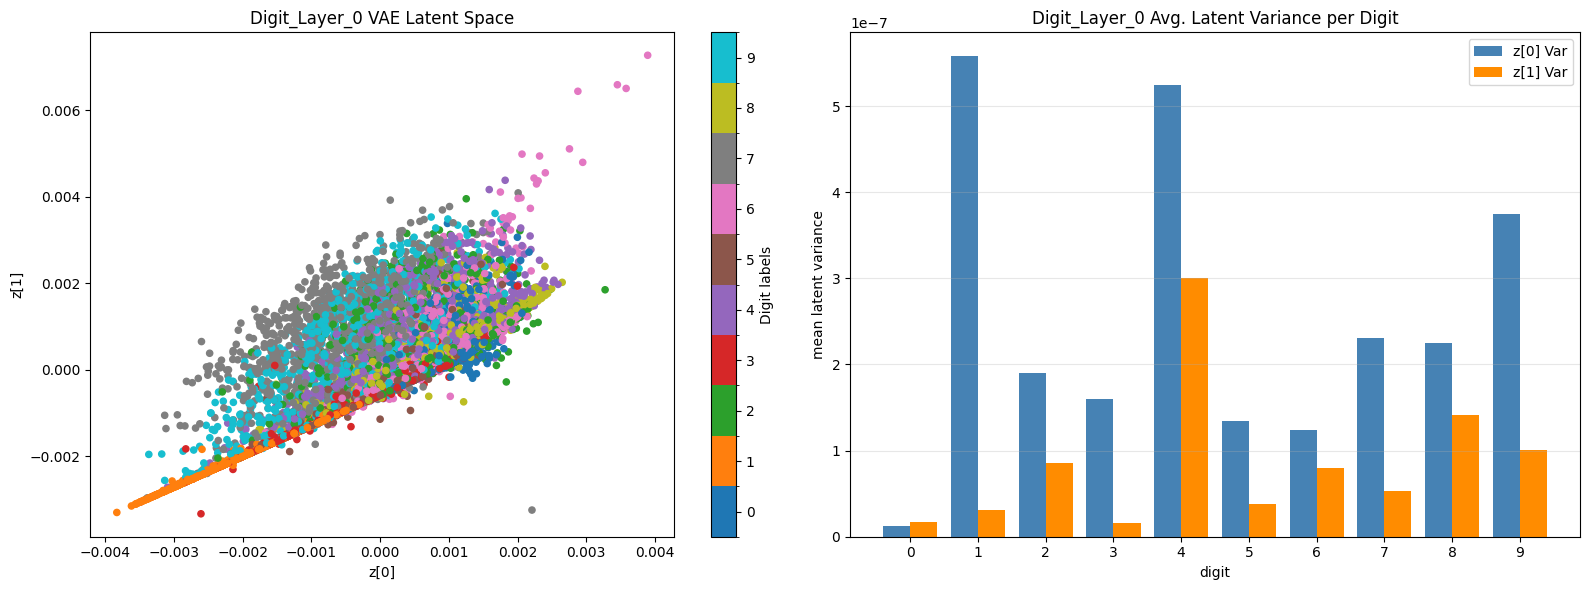

In [11]:
graph_VAE_latent_space(first_layer_vae_model, first_digit_layer_X, "Digit_Layer_0")

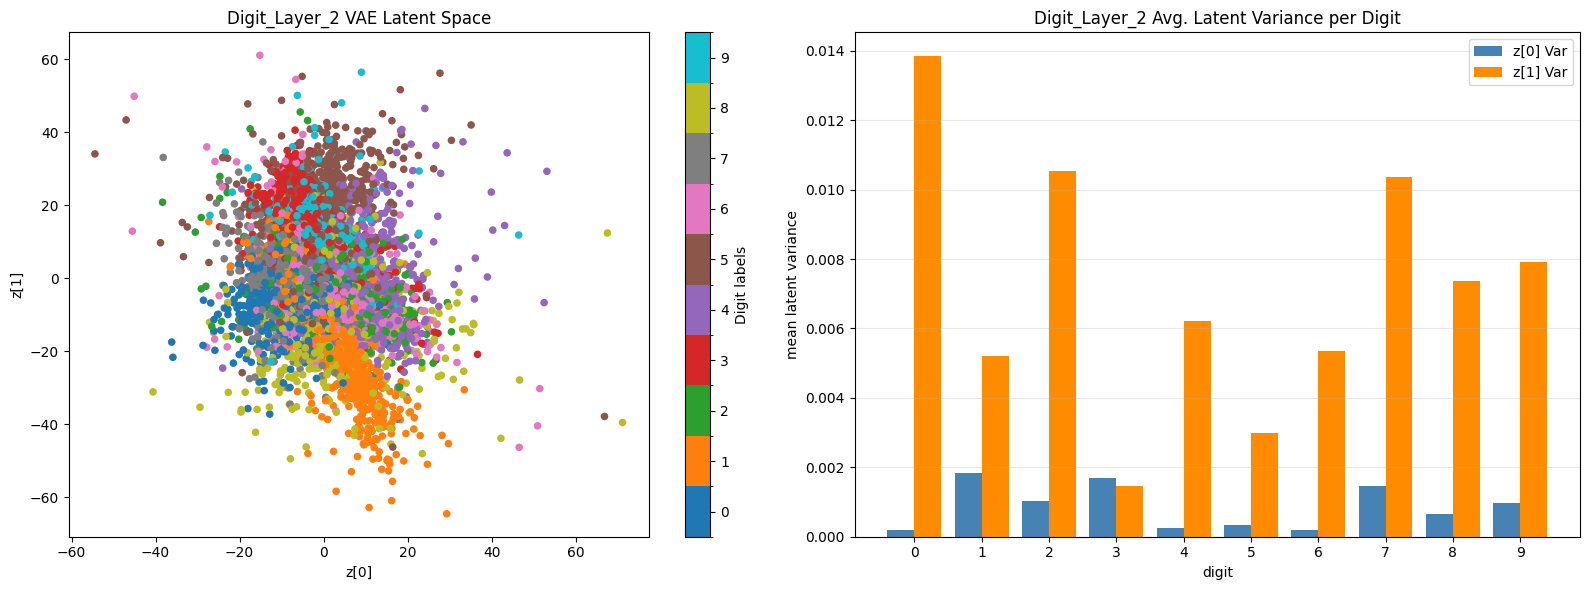

In [12]:
# 1) Get unaligned codes for both models (fit on these)
def _mu(vae, X):
    vae.eval()
    with torch.no_grad():
        mu, _ = vae.encoder(X)
    return mu.cpu().numpy()

Z_first = _mu(first_layer_vae_model, first_digit_layer_X)
Z_last  = _mu(last_layer_vae_model,  last_digit_layer_X)

# 2) Fit last -> first (anchor = first)
tf_last_to_first = fit_procrustes_similarity(Z_first, Z_last, center=True, scale=True)

graph_VAE_latent_space(last_layer_vae_model, last_digit_layer_X, "Digit_Layer_2", transform=tf_last_to_first)

In [13]:
def MSE_latent_penalty(mu_student, mu_teacher, normalize=True, per_dim=False):
    """
    MSE between student and teacher latent means, on the SAME examples.

    Args:
        mu_student: [B, D] student mu (differentiable)
        mu_teacher: [B, D] teacher mu (same row correspondence)
        normalize:  if True, divide by teacher variance so the term is scale-free
        per_dim:    if True, return per-dimension MSE [D] instead of a scalar

    Returns:
        scalar (or [D]) tensor
    """
    if per_dim:
        mse = (mu_student - mu_teacher).pow(2).mean(dim=0)   # [D]
        return mse / (mu_teacher.var(dim=0, unbiased=False) + 1e-8) if normalize else se
    mean_mse_across_dims = (mu_student - mu_teacher).pow(2).mean()
    if normalize:
        mean_mse_across_dims = mean_mse_across_dims / (mu_teacher.var(unbiased=False) + 1e-8)
    return mean_mse_across_dims

def train_VAE_with_MSE(X, likelihood, batch_size, n_epochs, learning_rate,
                       teacher_model, mse_lambda=0.1, latent_dim=2):
    assert likelihood in ("gaussian", "poisson")
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True)

    input_dim = X.shape[1]
    vae_model = VAE(input_dim=input_dim, latent_dim=latent_dim,
                    likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=learning_rate)

    # Initialize log records
    train_losses = recon_losses = kl_losses = mse_losses = []
    vae_model.train()
    for epoch in range(n_epochs + 1):
        # Reset cumulative loss vars
        tot = rec = kl = mse = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()
            recon, mu, logvar = vae_model(xb)

            # Calculate base VAE loss
            base_loss, recon_loss, kl_loss = vae_loss(recon, xb, mu, logvar, likelihood)

            # Find teacher latents for the same batch
            with torch.no_grad():
                mu_teacher, _ = teacher_model.encoder(xb)

            # Calculate MSE penalty
            mse_loss = MSE_latent_penalty(mu, mu_teacher)
            
            # Combine together for total loss, scaling mse_loss by mse_lambda
            mse_loss *= mse_lambda
            total = base_loss + mse_loss
            total.backward()
            optimizer.step()

            tot  += total.item()
            rec  += recon_loss.item()
            kl   += kl_loss.item()
            mse  += mse_loss.item()

        train_losses.append(tot); recon_losses.append(rec)
        kl_losses.append(kl); mse_losses.append(mse)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: total={tot:.3f} recon={rec:.3f} "
                  f"kl={kl:.3f} mse={mse:.3f}")

    logs = {"training_losses": train_losses, "recon_losses": recon_losses,
            "kl_losses": kl_losses, "mse_losses": mse_losses}
    return vae_model, logs

In [14]:
# Set training parameters 
n_epochs = 256
batch_size = 64
learning_rate = 1e-3 
likelihood = "gaussian"
teacher_model = first_layer_vae_model
mse_lambda = 100

# Train VAE model
last_layer_vae_model, logs = train_VAE_with_MSE(last_digit_layer_X, likelihood, batch_size, n_epochs, learning_rate,
                                       teacher_model, mse_lambda=mse_lambda, latent_dim=2)

epoch 0: total=59595286.242 recon=178.210 kl=2.277 mse=59595105.178


epoch 10: total=806497.894 recon=171.324 kl=0.078 mse=806326.489


epoch 20: total=733409.937 recon=171.371 kl=0.061 mse=733238.505


epoch 30: total=178704.502 recon=170.912 kl=0.030 mse=178533.560


epoch 40: total=259751.341 recon=170.982 kl=0.020 mse=259580.340


epoch 50: total=157509.032 recon=170.592 kl=0.016 mse=157338.425


... (16 outputs left out)

epoch 220: total=1994.512 recon=170.378 kl=0.000 mse=1824.133


epoch 230: total=2132.065 recon=170.549 kl=0.000 mse=1961.516


epoch 240: total=2003.717 recon=170.383 kl=0.000 mse=1833.333


epoch 250: total=1946.004 recon=170.491 kl=0.000 mse=1775.513


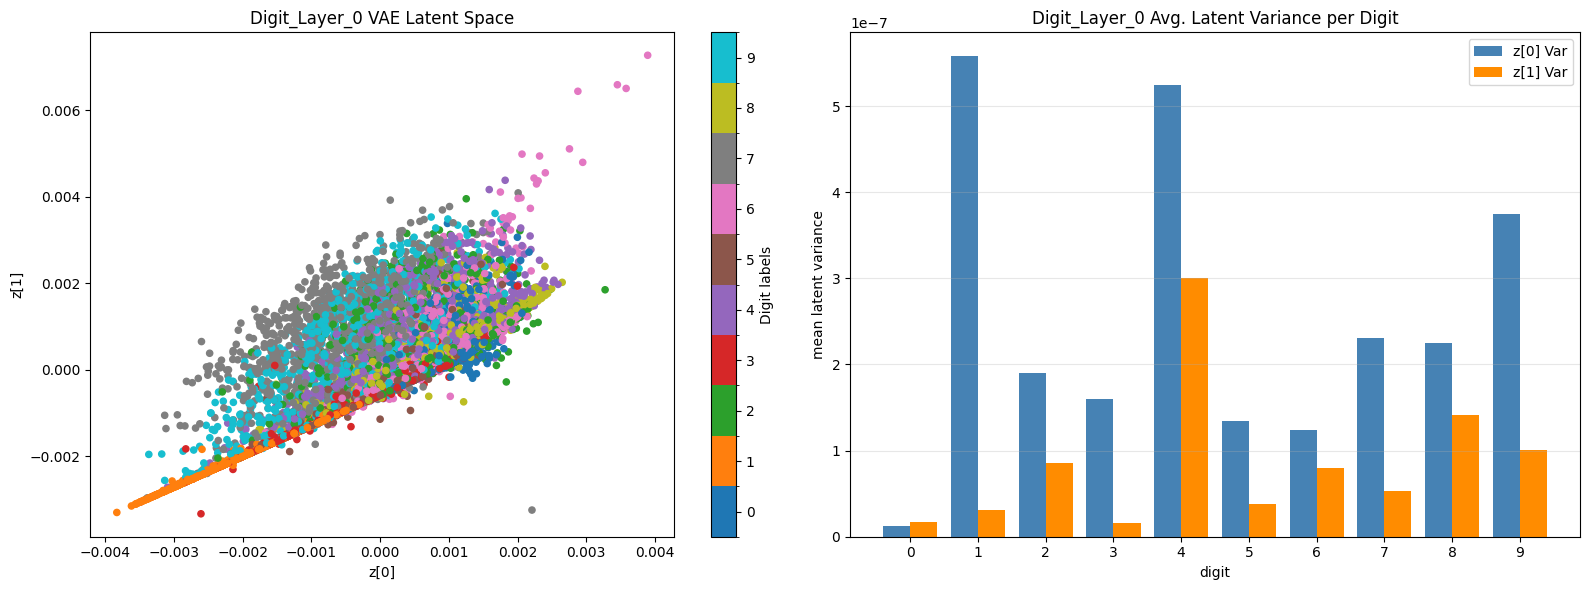

In [15]:
graph_VAE_latent_space(first_layer_vae_model, first_digit_layer_X, "Digit_Layer_0")

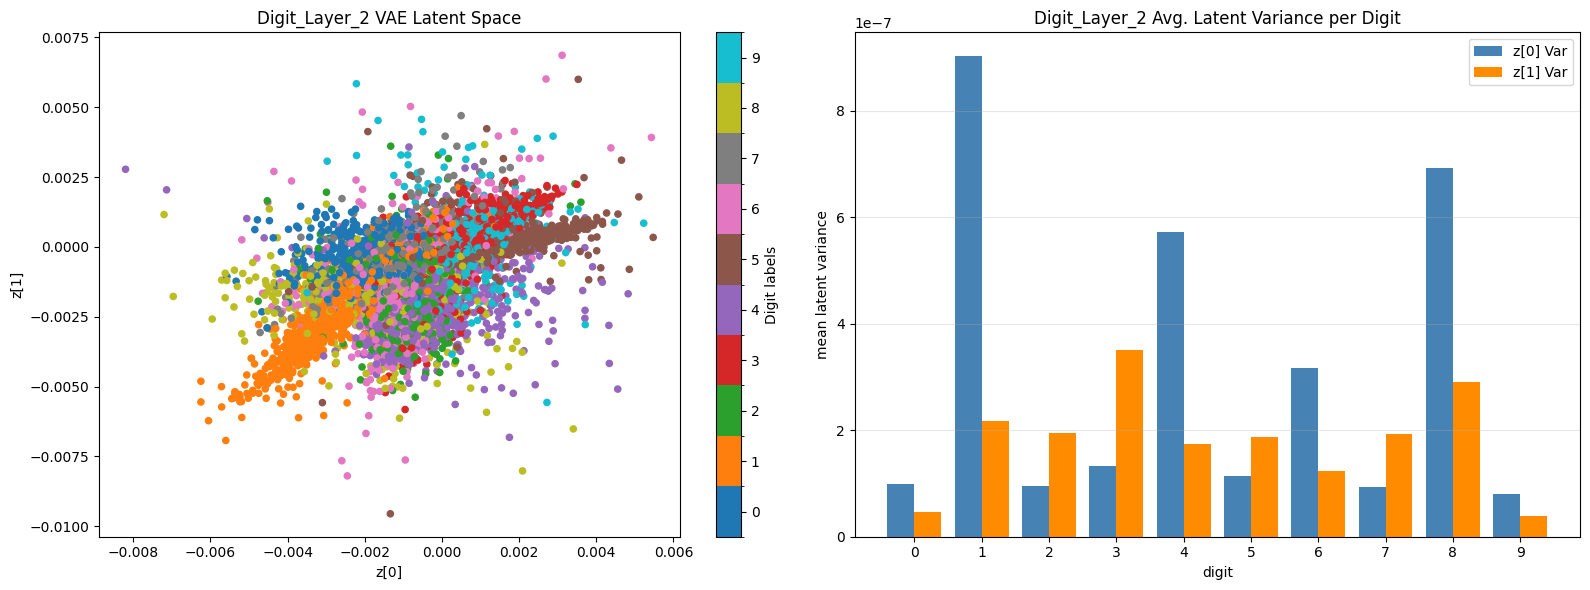

In [16]:
graph_VAE_latent_space(last_layer_vae_model, last_digit_layer_X, "Digit_Layer_2")

In [17]:
def relative_rep(mu, anchors):
    """mu: [B, D], anchors: [K, D] -> [B, K]"""
    mu_n = F.normalize(mu, dim=1)
    a_n = F.normalize(anchors, dim=1)
    return mu_n @ a_n.T   # cosine similarity

def train_VAE_with_relative_align(student_X, likelihood, batch_size, n_epochs, learning_rate,
                                  teacher_model, teacher_X, anchor_indices, rel_lambda=1.0,
                                  latent_dim=2, kl_warmup_epochs=0):
    # Keep track of index labels so that we can sync up a batch from student_X with the same entries in teacher_X
    index_labels = torch.arange(len(student_X))
    loader = DataLoader(TensorDataset(student_X, index_labels), batch_size=batch_size, shuffle=True)
    vae_model = VAE(input_dim=student_X.shape[1], latent_dim=latent_dim,
                    likelihood=likelihood).to(device)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=learning_rate)

    # Precompute teacher's anchor latents (these anchors do not change)
    with torch.no_grad():
        teacher_mu_anchors, _ = teacher_model.encoder(teacher_X[anchor_indices])

    # Initialize log records
    train_losses = recon_losses = kl_losses = rel_losses = []
    vae_model.train()
    for epoch in range(n_epochs + 1):
        # Reset cumulative loss vars
        tot = rec = kl = rel = 0.0
        kl_w = min(1.0, epoch / kl_warmup_epochs) if kl_warmup_epochs > 0 else 1.0
        for (xb, batch_idx) in loader:
            optimizer.zero_grad()
            recon, student_mu, logvar = vae_model(xb)
            base_loss, recon_loss, kl_loss = vae_loss(recon, xb, student_mu, logvar, likelihood)

            
            # Compute student anchor positions
            student_mu_anchors, _ = vae_model.encoder(student_X[anchor_indices])
            # Computer teacher batch positions
            with torch.no_grad():
                teacher_mu, _ = teacher_model.encoder(teacher_X[batch_idx])
            
            rel_student = relative_rep(student_mu, student_mu_anchors)
            rel_teacher = relative_rep(teacher_mu, teacher_mu_anchors)

            rel_loss = F.mse_loss(rel_student, rel_teacher)
            rel_loss *= rel_lambda
            total = recon_loss + kl_w * kl_loss + rel_loss
            total.backward()
            optimizer.step()

            tot  += total.item()
            rec  += recon_loss.item()
            kl   += kl_loss.item()
            rel  += rel_loss.item()

        train_losses.append(tot); recon_losses.append(rec)
        kl_losses.append(kl); rel_losses.append(rel)
        if epoch % 10 == 0:
            print(f"epoch {epoch}: total={tot:.3f} recon={rec:.3f} "
                  f"kl={kl:.3f} rel={rel:.3f}")

    logs = {"training_losses": train_losses, "recon_losses": recon_losses,
            "kl_losses": kl_losses, "rel_losses": rel_losses}
    return vae_model, logs

In [18]:
# Set training parameters 
n_epochs = 200
batch_size = 64
learning_rate = 1e-3 
likelihood = "gaussian"
teacher_model = first_layer_vae_model
rel_lambda = 25

anchor_indices = np.random.choice(range(last_digit_layer_X.shape[0]), 100)

# Train VAE model
last_layer_vae_model, logs = train_VAE_with_relative_align(last_digit_layer_X, likelihood, batch_size, n_epochs, learning_rate,
                                       teacher_model, first_digit_layer_X, anchor_indices, rel_lambda=rel_lambda, latent_dim=2)

epoch 0: total=2014.018 recon=168.491 kl=47.121 rel=1798.406


epoch 10: total=913.136 recon=164.656 kl=39.678 rel=708.802


epoch 20: total=736.065 recon=166.690 kl=32.199 rel=537.176


epoch 30: total=676.062 recon=166.099 kl=33.886 rel=476.076


epoch 40: total=681.157 recon=165.992 kl=33.329 rel=481.837


epoch 50: total=565.776 recon=164.916 kl=33.050 rel=367.809


... (11 outputs left out)

epoch 170: total=405.745 recon=167.874 kl=16.523 rel=221.348


epoch 180: total=320.216 recon=168.490 kl=15.368 rel=136.359


epoch 190: total=299.173 recon=168.445 kl=13.611 rel=117.117


epoch 200: total=317.645 recon=168.230 kl=15.435 rel=133.980


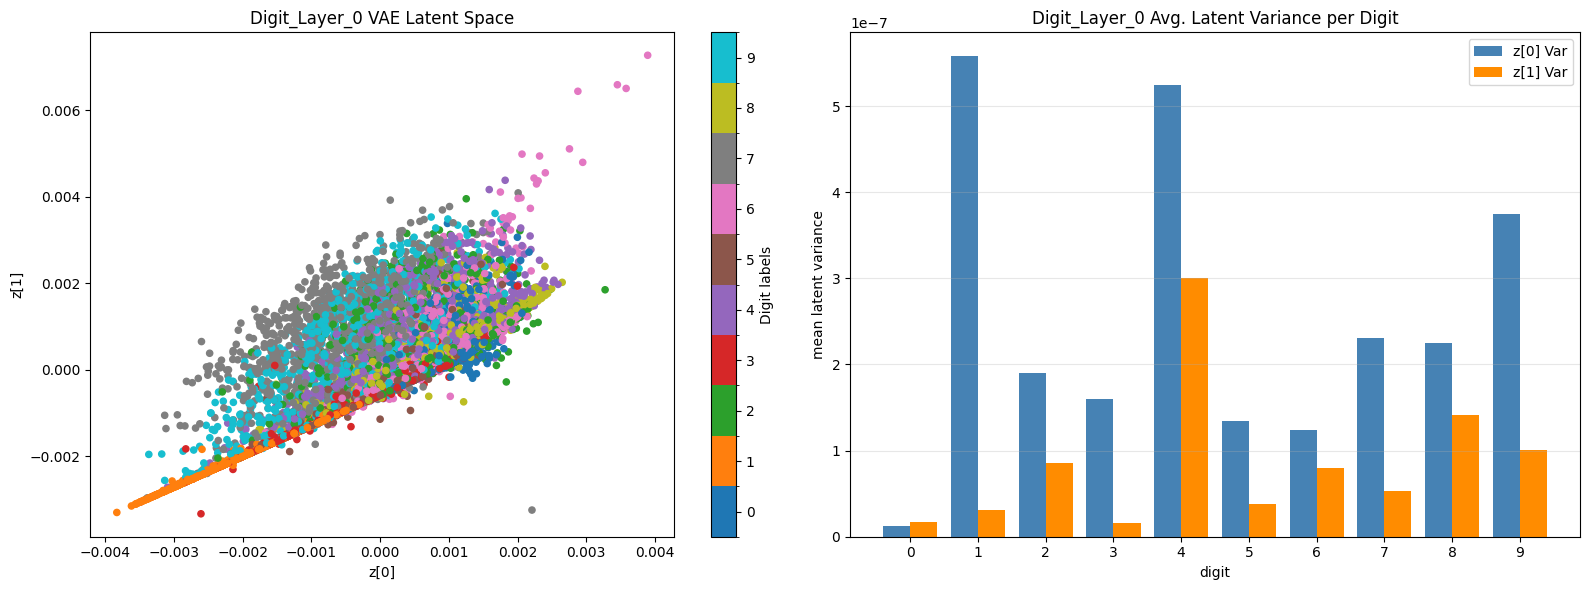

In [19]:
graph_VAE_latent_space(first_layer_vae_model, first_digit_layer_X, "Digit_Layer_0")

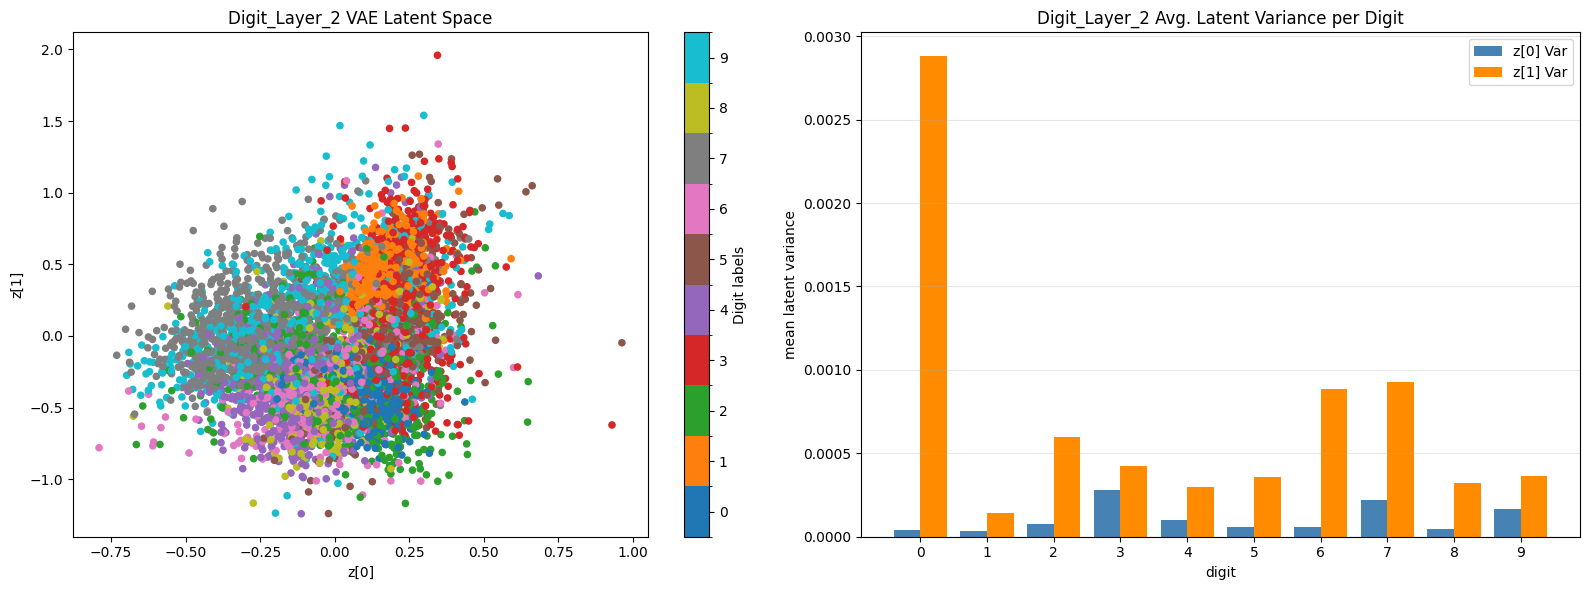

In [20]:
graph_VAE_latent_space(last_layer_vae_model, last_digit_layer_X, "Digit_Layer_2")

## Procrustes lambda sweep: unconstrained vs. constrained

Train the last-layer VAE with `train_VAE_with_procrustes` at several values of `proc_lambda` (λ = 0 is unconstrained). Every run is then scored the same way after training: its Procrustes distance to the teacher (the first-layer VAE) and its reconstruction and KL losses. Each latent space is also Procrustes-aligned onto the teacher for plotting.

In [21]:
import numpy as np

def _sweep_encode(vae, X):
    """Deterministic latent means for all of X, as a numpy array."""
    vae.eval()
    with torch.no_grad():
        mu, _ = vae.encoder(X.to(device))
    return mu.cpu().numpy()


def _sweep_eval_losses(vae, X, likelihood):
    """Final reconstruction / KL on the full dataset (decoding from mu, no sampling)."""
    vae.eval()
    with torch.no_grad():
        X = X.to(device)
        mu, logvar = vae.encoder(X)
        recon = vae.decoder(mu)
        _, recon_loss, kl_loss = vae_loss(recon, X, mu, logvar, likelihood)
    return recon_loss.item(), kl_loss.item()


def run_procrustes_lambda_sweep(teacher_vae, teacher_X, student_X, lambdas, seeds=(0,),
                                n_epochs=100, batch_size=64, learning_rate=1e-3,
                                likelihood="gaussian", latent_dim=2):
    """
    Train one last-layer VAE per (lambda, seed) with train_VAE_with_procrustes.
    lambda = 0 is the unconstrained baseline (the penalty is multiplied by 0).

    After training, every model is scored the same way on the full dataset:
      - procrustes_dist: scale-free Procrustes distance between student and teacher latents
                         (same formula as the training penalty; 0 = identical up to rotation/scale)
      - recon, kl:       final reconstruction and KL loss
    Returns a list of dicts, one per run.
    """
    Z_teacher = _sweep_encode(teacher_vae, teacher_X)
    results = []

    for lam in lambdas:
        for seed in seeds:
            print(f"\n===== lambda = {lam}, seed = {seed} =====")
            torch.manual_seed(seed)
            np.random.seed(seed)

            student, logs = train_VAE_with_procrustes(student_X, likelihood, batch_size, n_epochs,
                                                      learning_rate, teacher_vae,
                                                      proc_lambda=lam, latent_dim=latent_dim)

            Z_student = _sweep_encode(student, student_X)
            dist = procrustes_latent_penalty(torch.tensor(Z_student), torch.tensor(Z_teacher)).item()
            recon, kl = _sweep_eval_losses(student, student_X, likelihood)

            # Align student -> teacher (for plotting only)
            tf = fit_procrustes_similarity(Z_student, Z_teacher, center=True, scale=True)
            Z_aligned = apply_procrustes_similarity(Z_student, tf)

            print(f"-> procrustes_dist={dist:.4f}  recon={recon:.4f}  kl={kl:.4f}")
            results.append({"lambda": lam, "seed": seed, "model": student, "logs": logs,
                            "procrustes_dist": dist, "recon": recon, "kl": kl,
                            "Z_aligned": Z_aligned})
    return results


def plot_procrustes_lambda_sweep(results, teacher_vae, teacher_X):
    """
    Figure 1: Procrustes distance to teacher, reconstruction loss and KL vs. lambda (tradeoff curves).
    Figure 2: teacher latent space + each lambda's student latent space aligned onto the teacher.
    """
    lambdas = sorted({r["lambda"] for r in results})
    digits_np = np.asarray([int(d) for d in digit_labels])

    # ---- Figure 1: tradeoff curves ----
    metrics = [("procrustes_dist", "Procrustes distance to teacher"),
               ("recon", "Reconstruction loss"),
               ("kl", "KL divergence")]
    nonzero = [l for l in lambdas if l > 0]
    linthresh = min(nonzero) if nonzero else 1.0

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (key, title) in zip(axes, metrics):
        means = [np.mean([r[key] for r in results if r["lambda"] == l]) for l in lambdas]
        stds  = [np.std([r[key] for r in results if r["lambda"] == l]) for l in lambdas]
        ax.errorbar(lambdas, means, yerr=stds, marker="o", capsize=4)
        ax.set_xscale("symlog", linthresh=linthresh)   # symlog so lambda = 0 can be shown
        ax.set_xlabel("proc_lambda")
        ax.set_title(f"{title} vs. lambda")
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ---- Figure 2: aligned latent spaces (first seed of each lambda) ----
    cmap = plt.get_cmap("tab10")
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-1/2, 10), ncolors=10)

    Z_teacher = _sweep_encode(teacher_vae, teacher_X)
    panels = [("Teacher (Digit_Layer_0)", Z_teacher)]
    for l in lambdas:
        r = next(r for r in results if r["lambda"] == l)
        label = "unconstrained" if l == 0 else "constrained"
        panels.append((f"lambda = {l} ({label})\ndist = {r['procrustes_dist']:.3f}", r["Z_aligned"]))

    n_cols = 4
    n_rows = int(np.ceil(len(panels) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows), squeeze=False)
    for ax, (title, Z) in zip(axes.flat, panels):
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=digits_np, cmap=cmap, norm=norm, s=5)
        ax.set_title(title)
        ax.set_xlabel("z[0]")
        ax.set_ylabel("z[1]")
    for ax in list(axes.flat)[len(panels):]:
        ax.axis("off")
    fig.colorbar(sc, ax=axes, ticks=range(10), label="Digit labels")
    fig.suptitle("Last-layer VAE latent space, Procrustes-aligned onto the teacher")
    plt.show()


===== lambda = 0, seed = 0 =====


epoch 0: total=177.827 recon=176.359 kl=1.468 proc=0.000


epoch 10: total=171.490 recon=171.201 kl=0.289 proc=0.000


epoch 20: total=171.079 recon=171.014 kl=0.066 proc=0.000


epoch 30: total=170.834 recon=170.803 kl=0.031 proc=0.000


epoch 40: total=170.782 recon=170.766 kl=0.015 proc=0.000


... (68 outputs left out)

epoch 70: total=50016.812 recon=166.941 kl=28.141 proc=49821.730


epoch 80: total=43988.881 recon=166.660 kl=31.078 proc=43791.143


epoch 90: total=42069.102 recon=166.498 kl=34.745 proc=41867.858


epoch 100: total=38048.054 recon=166.096 kl=38.460 proc=37843.498
-> procrustes_dist=1.8411  recon=1.0370  kl=0.2473


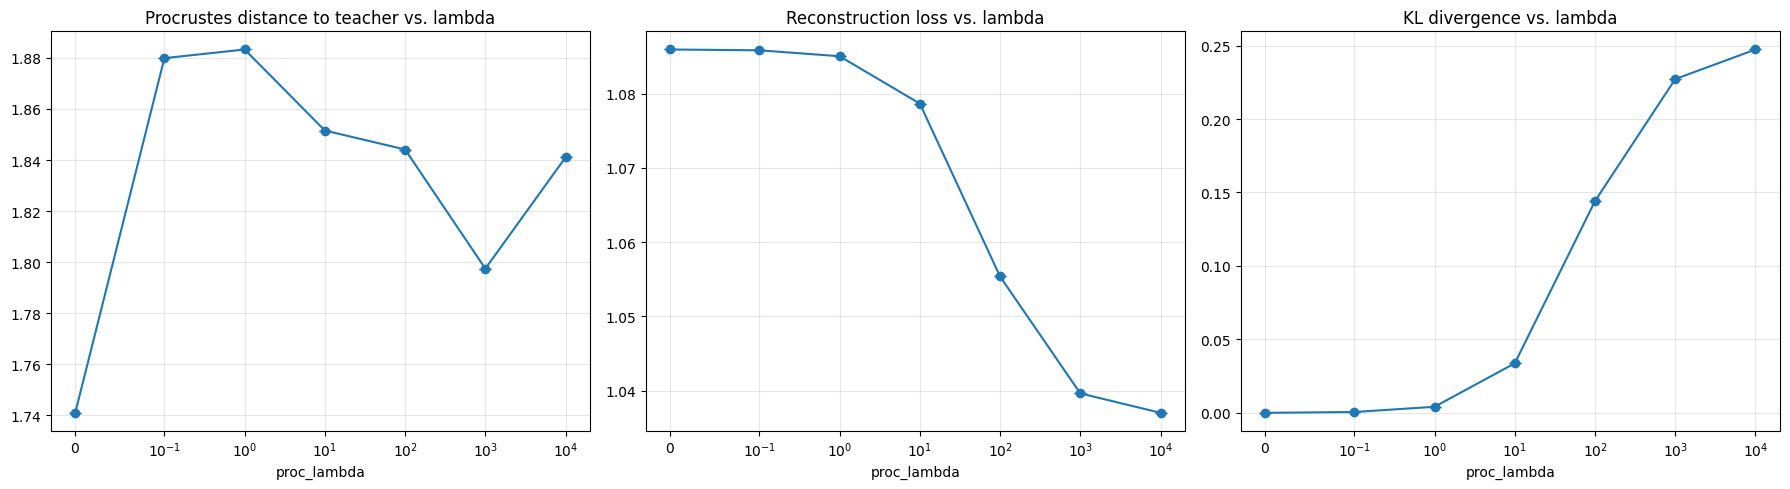

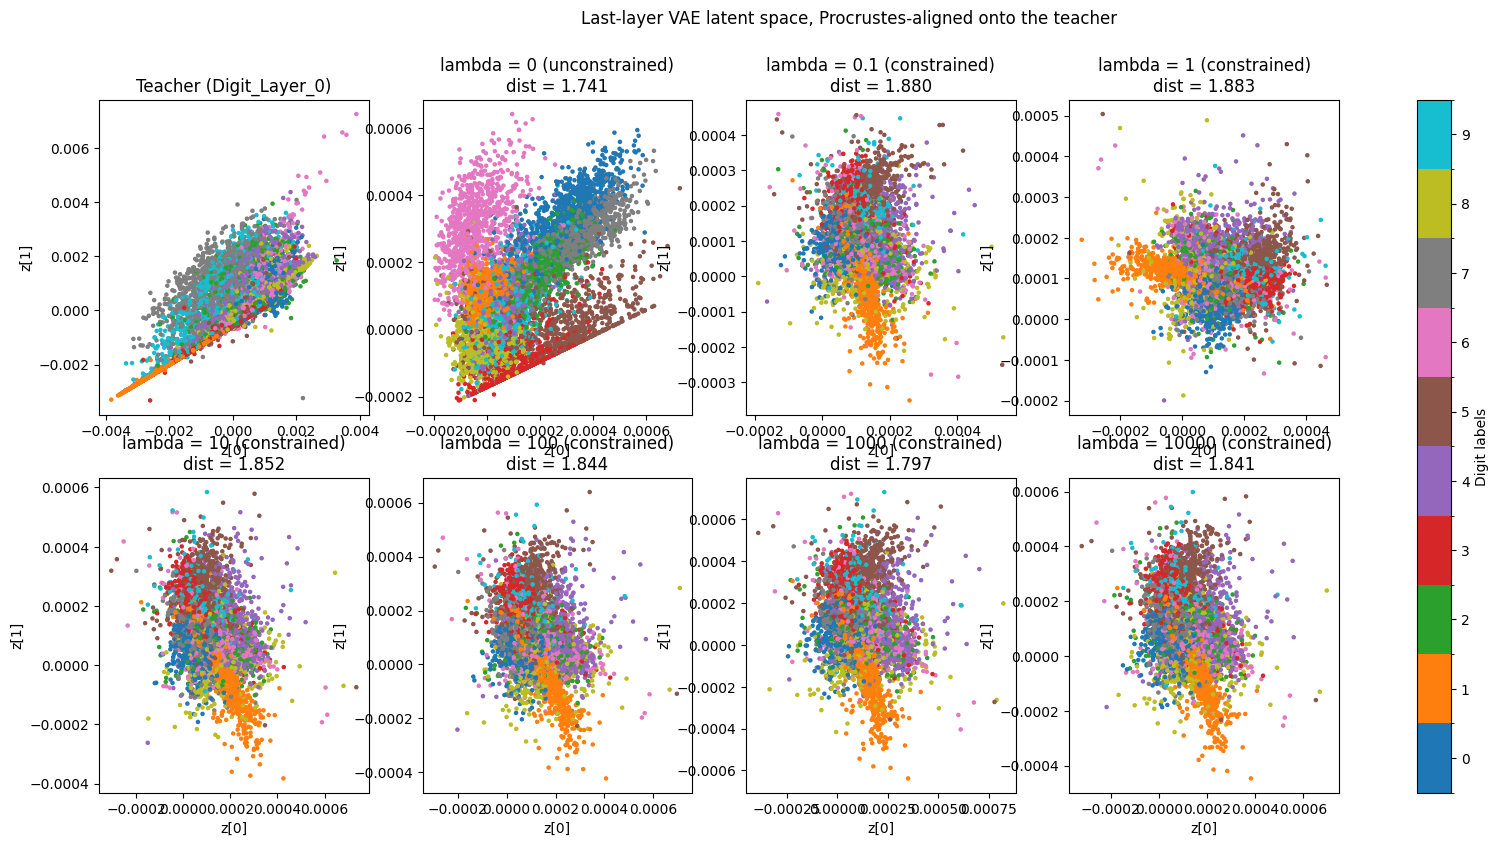

In [22]:
# Run the sweep: lambda = 0 is the unconstrained baseline, larger lambdas are increasingly constrained
sweep_lambdas = [0, 0.1, 1, 10, 100, 1000, 10000]
sweep_seeds = [0]   # add more seeds (e.g. [0, 1, 2]) to get error bars

sweep_results = run_procrustes_lambda_sweep(
    teacher_vae=first_layer_vae_model,
    teacher_X=first_digit_layer_X,
    student_X=last_digit_layer_X,
    lambdas=sweep_lambdas,
    seeds=sweep_seeds,
    n_epochs=100,
    batch_size=64,
    learning_rate=1e-3,
    likelihood="gaussian",
)

plot_procrustes_lambda_sweep(sweep_results, first_layer_vae_model, first_digit_layer_X)

In [23]:
from IPython.display import display, Markdown

def summarize_procrustes_lambda_sweep(results):
    """
    Print the numbers for every lambda, then highlight the actual difference between
    the unconstrained model (lambda = 0) and the most constrained model (largest lambda).
    """
    lambdas = sorted({r["lambda"] for r in results})
    assert 0 in lambdas, "Need lambda = 0 in the sweep as the unconstrained baseline."

    def avg(l, key):
        return float(np.mean([r[key] for r in results if r["lambda"] == l]))

    base_dist, base_recon, base_kl = avg(0, "procrustes_dist"), avg(0, "recon"), avg(0, "kl")

    # Table for every lambda, with differences relative to the unconstrained run
    rows = ["| lambda | Procrustes dist | Δ dist vs. unconstrained | recon | Δ recon vs. unconstrained | KL |",
            "|---|---|---|---|---|---|"]
    for l in lambdas:
        d, rc, k = avg(l, "procrustes_dist"), avg(l, "recon"), avg(l, "kl")
        rows.append(f"| {l} | {d:.4f} | {d - base_dist:+.4f} | {rc:.4f} | {rc - base_recon:+.4f} | {k:.4f} |")
    display(Markdown("### Lambda sweep results\n" + "\n".join(rows)))

    # Headline: unconstrained vs. most constrained
    lam_max = max(lambdas)
    con_dist, con_recon = avg(lam_max, "procrustes_dist"), avg(lam_max, "recon")
    dist_diff = con_dist - base_dist
    dist_pct = 100 * dist_diff / base_dist if base_dist > 0 else float("nan")
    recon_diff = con_recon - base_recon
    recon_pct = 100 * recon_diff / base_recon if base_recon > 0 else float("nan")

    display(Markdown(
        f"> ## ⭐ Unconstrained vs. constrained (λ = {lam_max})\n"
        f"> - **Procrustes distance to teacher:** unconstrained = **{base_dist:.4f}**, "
        f"constrained = **{con_dist:.4f}**\n"
        f"> - **Difference (constrained − unconstrained): {dist_diff:+.4f}** ({abs(dist_pct):.1f}% {'farther from' if dist_diff > 0 else 'closer to'} the teacher with the constraint)\n"
        f"> - **Reconstruction cost:** {base_recon:.4f} → {con_recon:.4f} "
        f"(**{recon_diff:+.4f}**, {recon_pct:+.1f}%)\n"
    ))
    return {"unconstrained_dist": base_dist, "constrained_dist": con_dist,
            "dist_difference": dist_diff, "dist_pct_change": dist_pct,
            "recon_difference": recon_diff, "recon_pct_change": recon_pct}

sweep_summary = summarize_procrustes_lambda_sweep(sweep_results)

### Lambda sweep results
| lambda | Procrustes dist | Δ dist vs. unconstrained | recon | Δ recon vs. unconstrained | KL |
|---|---|---|---|---|---|
| 0 | 1.7410 | +0.0000 | 1.0859 | +0.0000 | 0.0000 |
| 0.1 | 1.8799 | +0.1388 | 1.0858 | -0.0001 | 0.0006 |
| 1 | 1.8833 | +0.1422 | 1.0850 | -0.0009 | 0.0041 |
| 10 | 1.8516 | +0.1105 | 1.0787 | -0.0073 | 0.0337 |
| 100 | 1.8441 | +0.1031 | 1.0554 | -0.0306 | 0.1442 |
| 1000 | 1.7975 | +0.0564 | 1.0396 | -0.0463 | 0.2272 |
| 10000 | 1.8411 | +0.1000 | 1.0370 | -0.0489 | 0.2473 |

> ## ⭐ Unconstrained vs. constrained (λ = 10000)
> - **Procrustes distance to teacher:** unconstrained = **1.7410**, constrained = **1.8411**
> - **Difference (constrained − unconstrained): +0.1000** (5.7% farther from the teacher with the constraint)
> - **Reconstruction cost:** 1.0859 → 1.0370 (**-0.0489**, -4.5%)
